<a href="https://colab.research.google.com/github/HC-AIGroup/CS5330_F26/blob/main/MODULE%207/RAFT_vs_Farneback_vs_LK.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# RAFT vs Farnebäck vs Lucas-Kanade
We create frame 2 ourselves (shift or rotation), so we know the **true motion** of every pixel and can measure each method's **error** (endpoint error, EPE, in pixels; lower is better).

**Runtime → Change runtime type → T4 GPU** (RAFT also runs on CPU, just slower).

In [14]:
import cv2, numpy as np, torch, time
import matplotlib.pyplot as plt
from skimage import data
from torchvision.models.optical_flow import raft_large, Raft_Large_Weights
from torchvision.utils import flow_to_image

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cuda


## 1 · Two frames with known motion
Choose `MOTION = "shift"` (3 px right, 2 px down) or `"rotate"` (8° around the center).

In [15]:
MOTION = "rotate"                       # "shift" or "rotate"
S = 256                                  # RAFT needs height and width divisible by 8
f1 = cv2.resize(data.camera(), (S, S))   # grayscale test image

if MOTION == "shift":
    M = np.float32([[1, 0, 3], [0, 1, 2]])
else:
    M = cv2.getRotationMatrix2D((S / 2, S / 2), 8, 1.0)
f2 = cv2.warpAffine(f1, M, (S, S), borderMode=cv2.BORDER_REFLECT)

# true motion of every pixel: where (x, y) goes, minus (x, y)
yy, xx = np.mgrid[0:S, 0:S].astype(np.float32)
true = np.stack([M[0,0]*xx + M[0,1]*yy + M[0,2] - xx,
                 M[1,0]*xx + M[1,1]*yy + M[1,2] - yy], axis=-1)
print("true motion: up to", np.linalg.norm(true, axis=-1).max().round(1), "px")

true motion: up to 25.3 px


## 2 · RAFT
1. load the pretrained model (trained on synthetic data with known flow)
2. the model's own `transforms()` prepares both images
3. the model returns a **list** of flows, one per refinement step; the last one is the best

In [16]:
weights = Raft_Large_Weights.DEFAULT
model = raft_large(weights=weights, progress=False).to(device).eval()

def to_tensor(gray):                     # gray (H, W) -> RGB tensor (1, 3, H, W), uint8
    rgb = np.stack([gray] * 3, axis=0)
    return torch.from_numpy(rgb).unsqueeze(0)

img1, img2 = weights.transforms()(to_tensor(f1), to_tensor(f2))

with torch.no_grad():
    t0 = time.time()
    flows = model(img1.to(device), img2.to(device))     # list of 12 refinements
    t_raft = time.time() - t0
flow_raft = flows[-1][0].permute(1, 2, 0).cpu().numpy()  # (H, W, 2) -> u, v per pixel
print("refinement steps:", len(flows), "| flow shape:", flow_raft.shape, f"| time {t_raft:.2f} s")

refinement steps: 12 | flow shape: (256, 256, 2) | time 0.08 s


## 3 · Farnebäck and Lucas-Kanade on the same frames

In [17]:
t0 = time.time()
flow_fb = cv2.calcOpticalFlowFarneback(f1, f2, None, 0.5, 3, 15, 3, 5, 1.2, 0)
t_fb = time.time() - t0

# Lucas-Kanade on a grid of points (away from the borders)
gy, gx = np.mgrid[24:S-24:4, 24:S-24:4]
pts = np.stack([gx.ravel(), gy.ravel()], 1).astype(np.float32)
t0 = time.time()
p2, st, _ = cv2.calcOpticalFlowPyrLK(f1, f2, pts.reshape(-1, 1, 2), None,
                                     winSize=(15, 15), maxLevel=3)
t_lk = time.time() - t0
flow_lk = p2.reshape(-1, 2) - pts
found = st.ravel() == 1

## 4 · Compare: error against the true motion (same grid points for all three)

In [18]:
tg = true[gy.ravel(), gx.ravel()]
err = lambda f: np.linalg.norm(f - tg, axis=1)
e_lk = err(flow_lk)
e_fb = err(flow_fb[gy.ravel(), gx.ravel()])
e_rf = err(flow_raft[gy.ravel(), gx.ravel()])

print(f"{'method':<14}{'mean error':>11}{'within 0.5 px':>15}{'time':>9}")
for name, e, t in [("Lucas-Kanade", e_lk, t_lk), ("Farneback", e_fb, t_fb), ("RAFT", e_rf, t_raft)]:
    print(f"{name:<14}{e.mean():>9.2f} px{np.mean(e < 0.5)*100:>13.0f} %{t:>8.2f}s")
print(f"(Lucas-Kanade marked {np.mean(~found)*100:.0f}% of points as lost)")

method         mean error  within 0.5 px     time
Lucas-Kanade       3.08 px           50 %    0.04s
Farneback          3.68 px           40 %    0.02s
RAFT               0.12 px          100 %    0.08s
(Lucas-Kanade marked 14% of points as lost)


## 5 · Look at the flows
`flow_to_image` uses torchvision's color code (Middlebury style), slightly different from our HSV wheel: color = direction, strength = speed, white = no motion.

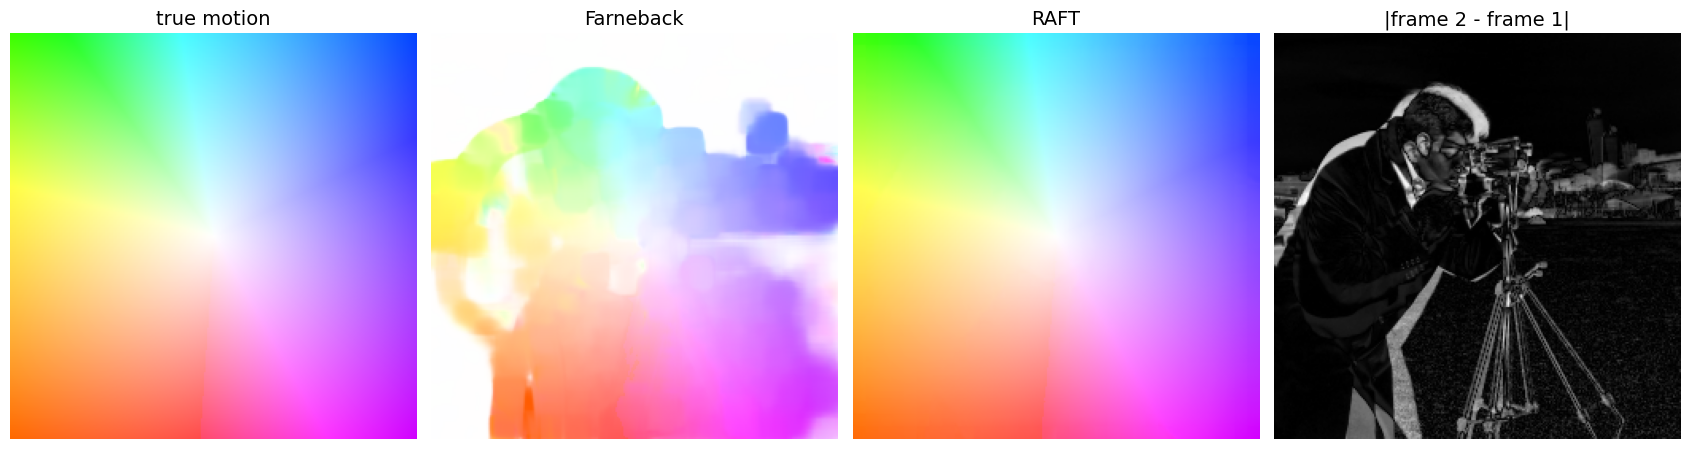

In [19]:
def show(flow):
    flow = np.ascontiguousarray(flow, dtype=np.float32)        # flow_to_image needs float32
    return flow_to_image(torch.from_numpy(flow).permute(2, 0, 1)).permute(1, 2, 0).numpy()

fig, ax = plt.subplots(1, 4, figsize=(17, 4.5))
for a, im, t in zip(ax, [show(true), show(flow_fb), show(flow_raft), np.abs(f2.astype(int) - f1)],
                    ["true motion", "Farneback", "RAFT", "|frame 2 - frame 1|"]):
    a.imshow(im, cmap="gray"); a.set_title(t, fontsize=14); a.axis("off")
plt.tight_layout(); plt.show()

## Discussion
- Which method is most accurate? Which is fastest?
- Where does Farnebäck fail (look at the flat sky)? Does RAFT fail there too?
- Change `MOTION` to `"shift"`, and the angle to 15°. What changes?